In [1]:
print("Python çalışıyor")

Python çalışıyor


In [1]:
import tensorflow as tf
print("TensorFlow sürümü:", tf.__version__)

TensorFlow sürümü: 2.21.0


In [2]:
import tensorflow as tf
import numpy as np

# Rastgelelik kontrolü
tf.keras.utils.set_random_seed(42)

# 3x3 boyutunda 16 filtreli konvolüsyon katmanı
conv = tf.keras.layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation='relu',
    kernel_initializer='he_normal'
)

# Örnek giriş görüntüsü
dummy_input = tf.random.normal((1, 128, 128, 1))

# Konvolüsyon işlemi
output = conv(dummy_input)

# Ağırlıkları al
weights, biases = conv.get_weights()

print("Giriş boyutu:", dummy_input.shape)
print("Çıkış boyutu:", output.shape)
print("Filtre ağırlıklarının boyutu:", weights.shape)
print("Bias boyutu:", biases.shape)

# İlk filtrenin ağırlıkları
print("İlk filtre:")
print(weights[:, :, 0, 0])

Giriş boyutu: (1, 128, 128, 1)
Çıkış boyutu: (1, 126, 126, 16)
Filtre ağırlıklarının boyutu: (3, 3, 1, 16)
Bias boyutu: (16,)
İlk filtre:
[[-0.25283593  0.12861036 -0.75786656]
 [-0.21681367 -0.15182823 -0.702172  ]
 [ 0.23038778  0.76512676 -0.74278826]]


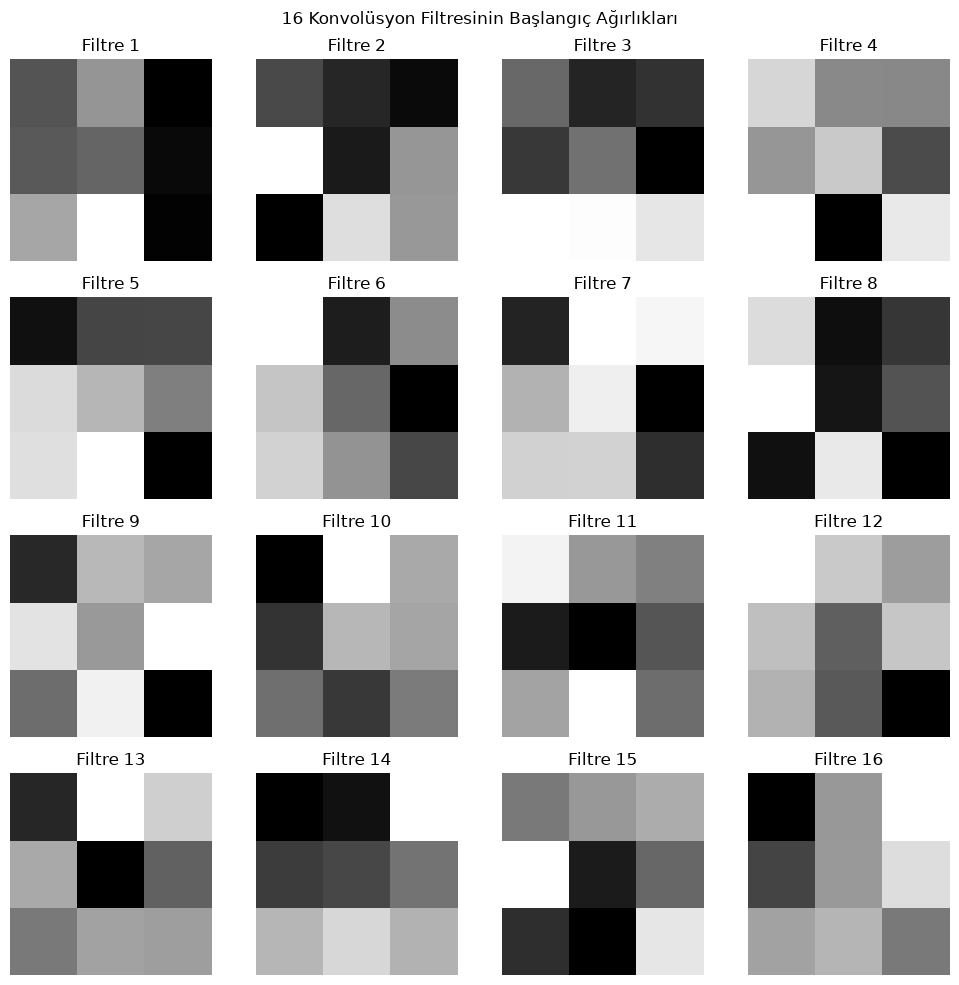

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    filtre = weights[:, :, 0, i]

    ax.imshow(filtre, cmap="gray")
    ax.set_title(f"Filtre {i + 1}")
    ax.axis("off")

plt.suptitle("16 Konvolüsyon Filtresinin Başlangıç Ağırlıkları")
plt.tight_layout()
plt.show()

In [4]:
import tensorflow as tf

# Örnek giriş matrisi
input_data = tf.constant([
    [[1., 3., 2., 4.],
     [5., 6., 1., 2.],
     [7., 2., 8., 3.],
     [4., 1., 5., 9.]]
])

# Boyutları düzenle: Batch, Height, Width, Channels
input_data = tf.reshape(input_data, (1, 4, 4, 1))

pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=2
)

output = pool(input_data)

print("Giriş:")
print(input_data.numpy()[0, :, :, 0])

print("Pooling sonucu:")
print(output.numpy()[0, :, :, 0])

Giriş:
[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [4. 1. 5. 9.]]
Pooling sonucu:
[[6. 4.]
 [7. 9.]]


In [5]:
import tensorflow as tf

x = tf.constant([-5., -2., -1., 0., 2., 4., 6.])

relu = tf.keras.layers.ReLU()

y = relu(x)

print("Giriş:", x.numpy())
print("ReLU çıkışı:", y.numpy())

Giriş: [-5. -2. -1.  0.  2.  4.  6.]
ReLU çıkışı: [0. 0. 0. 0. 2. 4. 6.]


In [6]:
import tensorflow as tf

logits = tf.constant([[2.0, 1.0, 0.1]])

softmax = tf.keras.layers.Softmax()

probabilities = softmax(logits)

print("Softmax sonuçları:")
print(probabilities.numpy())

print("Olasılıkların toplamı:")
print(tf.reduce_sum(probabilities).numpy())

Softmax sonuçları:
[[0.6590011  0.24243298 0.09856588]]
Olasılıkların toplamı:
0.99999994


In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Normalizasyon
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Kanal boyutu ekleme
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Eğitim verisi:", x_train.shape)
print("Test verisi:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Eğitim verisi: (60000, 28, 28, 1)
Test verisi: (10000, 28, 28, 1)


In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Birinci konvolüsyon
    tf.keras.layers.Conv2D(
        8, (3, 3),
        activation='relu'
    ),

    # Birinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),

    # İkinci konvolüsyon
    tf.keras.layers.Conv2D(
        16, (3, 3),
        activation='relu'
    ),

    # İkinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Çok boyutlu özellikleri tek boyuta dönüştür
    tf.keras.layers.Flatten(),

    # Tam bağlantılı katman
    tf.keras.layers.Dense(64, activation='relu'),

    # 10 sınıf için çıktı
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 26, 26, 8)           │              80 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 13, 13, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 11, 11, 16)          │           1,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 5, 5, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 400)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          25,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7749 - loss: 0.6187 - val_accuracy: 0.8240 - val_loss: 0.4769
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8495 - loss: 0.4156 - val_accuracy: 0.8470 - val_loss: 0.4227
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8651 - loss: 0.3726 - val_accuracy: 0.8588 - val_loss: 0.3934
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8738 - loss: 0.3466 - val_accuracy: 0.8655 - val_loss: 0.3778
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8801 - loss: 0.3259 - val_accuracy: 0.8693 - val_loss: 0.3609
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8674 - loss: 0.3726
Test Loss: 0.3726445138454437
Test Accuracy: 0.8673999905586243


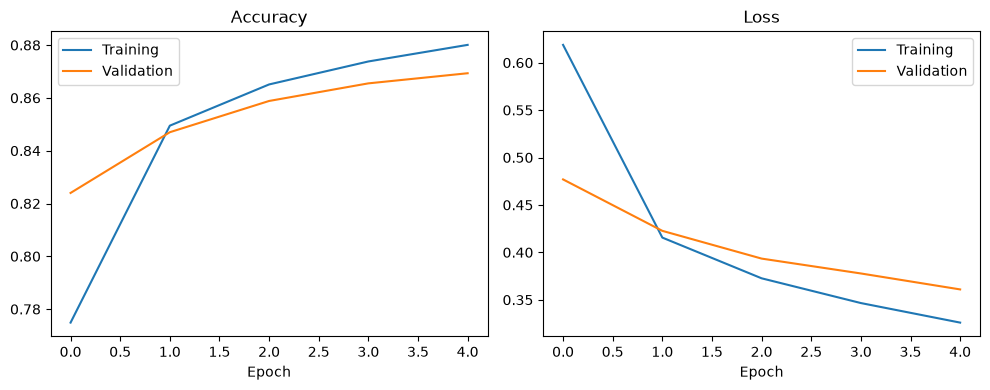

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
import time
import tensorflow as tf

def model_olustur(filtre_sayisi):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(
            filtre_sayisi, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(
            16, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

sonuclar = []

for filtre in [8, 16]:
    tf.keras.utils.set_random_seed(42)

    deney_modeli = model_olustur(filtre)

    deney_modeli.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    baslangic = time.perf_counter()

    deney_history = deney_modeli.fit(
        x_train,
        y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.1
    )

    sure = time.perf_counter() - baslangic

    test_loss, test_acc = deney_modeli.evaluate(
        x_test, y_test, verbose=0
    )

    sonuclar.append({
        "Filtre": filtre,
        "Egitim Dogrulugu": deney_history.history["accuracy"][-1],
        "Test Dogrulugu": test_acc,
        "Egitim Suresi (sn)": sure
    })

for sonuc in sonuclar:
    print(sonuc)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7696 - loss: 0.6288 - val_accuracy: 0.8203 - val_loss: 0.4840
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8468 - loss: 0.4236 - val_accuracy: 0.8432 - val_loss: 0.4283
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8642 - loss: 0.3764 - val_accuracy: 0.8600 - val_loss: 0.3908
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8750 - loss: 0.3461 - val_accuracy: 0.8665 - val_loss: 0.3622
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8819 - loss: 0.3249 - val_accuracy: 0.8728 - val_loss: 0.3431
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7809 - loss: 0.6118 - val_accuracy: 0.8303 - val_loss: 0.4730
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8547 - loss: 0.4028 - val_accuracy: 0.8580 - val_loss: 0.4013
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8715 - loss: 0.3564 - val_accuracy: 0.8680 - v